# Categorical Data Clustering: K-Means vs. Hierarchical Clustering

**Unsupervised learning · Python · scikit-learn**

This project compares clustering methods on a dataset of **1,000 observations and three nominal categorical features**. It explores one-hot encoding, cluster-number selection and the trade-off between compactness, separation and balanced cluster sizes.

> **Data provenance.** The original dataset used in a University of Bologna Machine Learning and Data Mining exam is no longer available. The file bundled here is a **synthetic replacement**, not a recovered copy. It reproduces the number of rows, categorical domain and approximate marginal frequencies from the saved analysis; its feature combinations and all clustering results are synthetic. Nothing here claims to reproduce the original exam scores.

Run the cells from top to bottom from the repository root. Figures are also saved in `figures/`.

## 1. Load and inspect the data

The features `F0`, `F1` and `F2` contain **nominal** values `a`–`j`; the letters have no inherent ordering. We inspect feature distributions and missing values before encoding.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
DATA_PATH = Path("data/synthetic_categorical_data.tsv")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 20)
df = pd.read_csv(DATA_PATH, sep="\t")
assert df.shape == (1000, 3), f"Unexpected dataset shape: {df.shape}"
assert list(df.columns) == ["F0", "F1", "F2"]
assert not df.isna().any().any(), "Dataset contains missing values"
display(df.head())
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

,F0,F1,F2
0,d,a,a
1,c,e,c
2,j,a,c
3,f,e,j
4,c,e,d


Shape: 1,000 rows x 3 columns


,F0,F1,F2
a,100,100,100
b,100,99,99
c,100,100,100
d,100,100,100
e,100,101,101
f,100,100,100
g,100,100,100
h,100,100,100
i,100,100,100
j,100,100,100


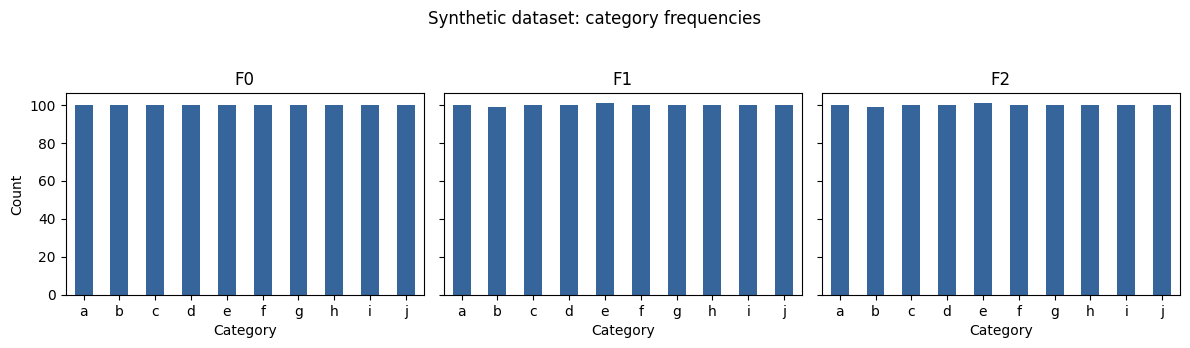

In [2]:
frequencies = pd.DataFrame({col: df[col].value_counts().sort_index() for col in df.columns}).fillna(0).astype(int)
display(frequencies)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for ax, col in zip(axes, df.columns):
    frequencies[col].plot.bar(ax=ax, color="#35659a", rot=0)
    ax.set_title(col)
    ax.set_xlabel("Category")
    ax.set_ylabel("Count")
fig.suptitle("Synthetic dataset: category frequencies", y=1.04, fontsize=12)
fig.tight_layout()
plt.show()

## 2. Encode categorical features

We use **one-hot encoding**, not ordinal encoding. This makes the representation invariant to an arbitrary alphabetical order. However, Euclidean distance on one-hot vectors is still a modeling choice, and K-Means centroids may not correspond to real category combinations. A categorical-specific method such as K-Modes would be an interesting extension.

In [3]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X = encoder.fit_transform(df)
print(f"Encoded shape: {X.shape}")
assert X.shape == (1000, 30)
print("Encoded features:", ", ".join(encoder.get_feature_names_out()[:10]), "...")

Encoded shape: (1000, 30)
Encoded features: F0_a, F0_b, F0_c, F0_d, F0_e, F0_f, F0_g, F0_h, F0_i, F0_j ...


## 3. Evaluation metrics

We evaluate candidate cluster counts with:

- **Inertia** (K-Means): sum of squared distances to cluster centers; lower values are expected as `k` increases and do *not* independently establish the best `k`.
- **Silhouette score**: measures separation and within-cluster cohesion; closer to 1 is usually better.
- **Balanced Partition Index (BPI)**: the coefficient of variation of cluster sizes. **Lower is more balanced**; `BPI = 0` means equally sized clusters. This metric measures **size balance only**, not whether clusters capture meaningful patterns.

$$BPI = \frac{\operatorname{std}(n_1,\ldots,n_k)}{\operatorname{mean}(n_1,\ldots,n_k)}$$

In [4]:
def balanced_partition_index(labels):
    _, counts = np.unique(labels, return_counts=True)
    if not len(counts) or np.mean(counts) == 0:
        raise ValueError("Cannot calculate BPI without nonempty clusters")
    return float(np.std(counts) / np.mean(counts))

assert balanced_partition_index([0, 0, 1, 1]) == 0.0
assert balanced_partition_index([0, 0, 0, 1]) > 0.0

## 4. K-Means: choose a cluster count

We fit `k = 2...10` with a fixed random seed and `n_init=20` to keep the comparison reproducible. Because the exercise explicitly prioritizes balanced sizes and the elbow/silhouette curves are not decisive, **we select the lowest BPI** in this predefined range, using silhouette only as a tie-breaker. This is a documented *design choice*, not a universal definition of optimal clustering.

In [5]:
k_candidates = range(2, 11)
kmeans_rows = []
for k in k_candidates:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X)
    kmeans_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "BPI": balanced_partition_index(labels),
    })
km_results = pd.DataFrame(kmeans_rows)
km_results.to_csv("results/kmeans_search.csv", index=False)
display(km_results.round(4))

,k,inertia,silhouette,BPI
0,2,2603.4702,0.0386,0.4760
1,3,2520.6826,0.0482,0.4045
2,4,2424.1701,0.0636,0.5821
3,5,2290.6780,0.0939,0.7746
4,6,2187.8960,0.1134,0.8944
5,7,2085.0100,0.1344,0.5099
6,8,1983.6100,0.1542,0.3464
7,9,1879.7193,0.1741,0.2829
8,10,1778.7893,0.1945,0.0045


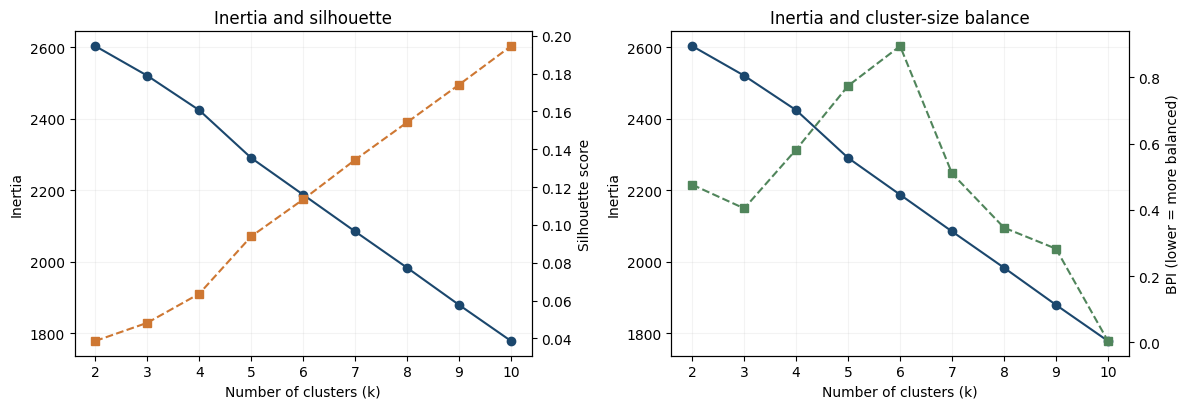

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(km_results["k"], km_results["inertia"], marker="o", label="Inertia", color="#1b476d")
ax1.set(xlabel="Number of clusters (k)", ylabel="Inertia", title="Inertia and silhouette")
ax1b = ax1.twinx()
ax1b.plot(km_results["k"], km_results["silhouette"], marker="s", linestyle="--", label="Silhouette", color="#ce7732")
ax1b.set_ylabel("Silhouette score")
ax2.plot(km_results["k"], km_results["inertia"], marker="o", label="Inertia", color="#1b476d")
ax2.set(xlabel="Number of clusters (k)", ylabel="Inertia", title="Inertia and cluster-size balance")
ax2b = ax2.twinx()
ax2b.plot(km_results["k"], km_results["BPI"], marker="s", linestyle="--", label="BPI", color="#50855b")
ax2b.set_ylabel("BPI (lower = more balanced)")
for a in (ax1, ax2):
    a.set_xticks(list(k_candidates))
    a.grid(alpha=.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
# Select using the stated goal: minimize cluster-size imbalance, then maximize silhouette.
selected_k = int(km_results.sort_values(["BPI", "silhouette"], ascending=[True, False]).iloc[0]["k"])
kmeans_final = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=20)
km_labels = kmeans_final.fit_predict(X)
km_summary = {
    "k": selected_k,
    "inertia": float(kmeans_final.inertia_),
    "silhouette": float(silhouette_score(X, km_labels)),
    "BPI": balanced_partition_index(km_labels),
}
print("Selected K-Means configuration:", {key: round(val, 5) for key, val in km_summary.items()})
assert np.isclose(km_summary["BPI"], km_results.loc[km_results.k == selected_k, "BPI"].iloc[0])

Selected K-Means configuration: {'k': 10, 'inertia': 1778.78926, 'silhouette': 0.1945, 'BPI': 0.00447}


## 5. Hierarchical clustering at the same `k`

To isolate the effect of the algorithm, we **hold `k` fixed** at the K-Means selection and compare four hierarchical linkages (`ward`, `average`, `single`, `complete`). We choose the linkage with the smallest BPI, again using silhouette to break ties. Unlike the original exam notebook, the automatically selected linkage is also the linkage used for the final fit.

In [8]:
linkages = ["ward", "average", "single", "complete"]
agg_rows = []
for linkage in linkages:
    model = AgglomerativeClustering(n_clusters=selected_k, linkage=linkage)
    labels = model.fit_predict(X)
    agg_rows.append({
        "linkage": linkage,
        "k": selected_k,
        "silhouette": silhouette_score(X, labels),
        "BPI": balanced_partition_index(labels),
    })
agg_results = pd.DataFrame(agg_rows).sort_values(["BPI", "silhouette"], ascending=[True, False]).reset_index(drop=True)
agg_results.to_csv("results/hierarchical_linkages.csv", index=False)
display(agg_results.round(4))
selected_linkage = str(agg_results.iloc[0]["linkage"])
agg_final = AgglomerativeClustering(n_clusters=selected_k, linkage=selected_linkage)
agg_labels = agg_final.fit_predict(X)
agg_summary = {
    "k": selected_k,
    "linkage": selected_linkage,
    "silhouette": float(silhouette_score(X, agg_labels)),
    "BPI": balanced_partition_index(agg_labels),
}
print("Selected hierarchical configuration:", {key: round(val, 5) if isinstance(val, float) else val for key, val in agg_summary.items()})
assert np.isclose(agg_summary["BPI"], agg_results.iloc[0]["BPI"])

,linkage,k,silhouette,BPI
0,average,10,0.0452,0.3515
1,ward,10,0.0381,0.5118
2,complete,10,0.0043,1.6002
3,single,10,-0.1821,2.9700


Selected hierarchical configuration: {'k': 10, 'linkage': 'average', 'silhouette': 0.04521, 'BPI': 0.35145}


## 6. Compare the selected cluster partitions

The x-axis labels are arbitrary cluster IDs (they are not aligned across algorithms). We compare **cluster-size distributions**, not the semantic identity of each cluster.

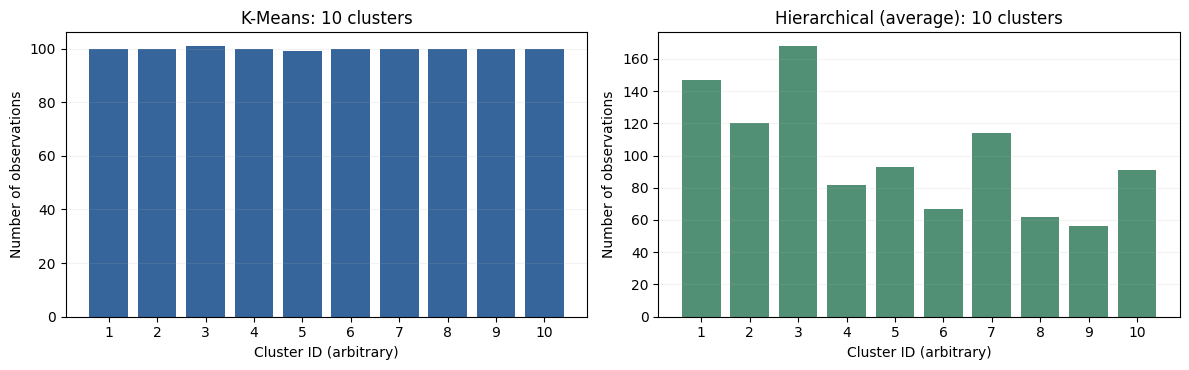

,method,k,inertia,silhouette,BPI,linkage
0,K-Means,10,1778.7893,0.1945,0.0045,NaN
1,Hierarchical (average),10,NaN,0.0452,0.3515,average


In [9]:
km_sizes = np.unique(km_labels, return_counts=True)[1]
agg_sizes = np.unique(agg_labels, return_counts=True)[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, counts, name, color in [
    (axes[0], km_sizes, "K-Means", "#35659a"),
    (axes[1], agg_sizes, f"Hierarchical ({selected_linkage})", "#529075"),
]:
    ax.bar(range(1, len(counts)+1), counts, color=color)
    ax.set_title(f"{name}: {len(counts)} clusters")
    ax.set(xlabel="Cluster ID (arbitrary)", ylabel="Number of observations")
    ax.set_xticks(range(1, len(counts)+1))
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "cluster_sizes.png", dpi=160, bbox_inches="tight")
plt.show()
comparison = pd.DataFrame([
    {"method": "K-Means", **km_summary},
    {"method": f"Hierarchical ({selected_linkage})", **agg_summary},
])
comparison.to_csv("results/final_comparison.csv", index=False)
display(comparison.round(4))

## 7. Interpretation and limitations

**What the numerical results do show:**

- Given the explicitly chosen priority of balanced cluster sizes, K-Means and hierarchical models can be compared with BPI alongside silhouette. The ranking and chosen configuration are computed automatically from the displayed results, not asserted in advance.
- The K-Means inertia decreases as `k` increases, as expected. Silhouette values for the synthetic data do not by themselves prove the presence of meaningful latent groups.
- Small BPI measures only the equality of group sizes; it is **not evidence of predictive accuracy, ground-truth classes or generalization**.

**Limits:** The categorical variables are represented by one-hot vectors and analyzed using Euclidean-distance-based algorithms. The synthetic attributes have no known ground-truth clusters, and the **original examination data and results cannot be reconstructed**. Alternative approaches such as K-Modes, multiple independent datasets and stability analysis could produce a more informative study. The search ends at `k=10`, so a best result at this boundary must not be presented as a global optimum.